# Train the NAFNet denoiser (free GPU)

Runs the training in this repo on a Colab T4, about an hour for the `nano`
architecture. Training on a laptop CPU is not practical.

**Set the runtime to GPU first:** Runtime → Change runtime type → T4 GPU.

At the end you download `nafnet.onnx` and copy it to the Jetson's
`models/` folder.

---

## About the data

The denoiser learns from **pairs**: a clean frame and a degraded copy. Those
two halves have different requirements, and conflating them is the usual way
this goes wrong.

| Half | Must be | Supplied by |
|---|---|---|
| **Degradation** — noise, blur, low light, JPEG | CCTV-specific | simulated in `degradations.py` |
| **Clean content** — texture, edge statistics | real photographs | cell 3b |

Procedural scenes (cell 3a) get the geometry right — camera height, perspective,
lighting pools, figures at depth-correct scale — but their surfaces are smooth
and their figures are flat. Train on those alone and the model concludes that
**smooth is always correct**, then wipes out the facial detail GFPGAN and
ArcFace depend on.

So run **both** 3a and 3b. The synthetic half teaches the scene; the real
photographs teach what detail looks like. Add your own footage when you have
it — that is strictly better than either.

In [1]:
#@title 1. Check the GPU
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader
import torch
print('torch', torch.__version__, '| cuda', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Runtime -> Change runtime type -> T4 GPU'

Tesla T4, 15360 MiB
torch 2.11.0+cu130 | cuda True


In [2]:
#@title 2. Get the code
!git clone -q https://github.com/Indumini2005/Re-id-techthrive.git
%cd Re-id-techthrive
!pip install -q onnx onnxsim onnxruntime
!ls

/content/Re-id-techthrive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 95.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 68.2 MB/s eta 0:00:00
arcface_faiss.py  gpfgan.py		    README.md
benchmark.py	  hub			    requirements-jetson.txt
check_device.py   main_pipeline.py	    requirements.txt
config.py	  nafnet_denoise.onnx	    training
denoise.py	  nafnet_denoise.onnx.data  yolocropping.py
enroll.py	  node_agent.py
export		  pipeline


  50 / 2000 frames (7 scenes)
  100 / 2000 frames (13 scenes)
  150 / 2000 frames (19 scenes)
  200 / 2000 frames (25 scenes)
  250 / 2000 frames (32 scenes)
  300 / 2000 frames (38 scenes)
  350 / 2000 frames (44 scenes)
  400 / 2000 frames (50 scenes)
  450 / 2000 frames (57 scenes)
  500 / 2000 frames (63 scenes)
  550 / 2000 frames (69 scenes)
  600 / 2000 frames (75 scenes)
  650 / 2000 frames (82 scenes)
  700 / 2000 frames (88 scenes)
  750 / 2000 frames (94 scenes)
  800 / 2000 frames (100 scenes)
  850 / 2000 frames (107 scenes)
  900 / 2000 frames (113 scenes)
  950 / 2000 frames (119 scenes)
  1000 / 2000 frames (125 scenes)
  1050 / 2000 frames (132 scenes)
  1100 / 2000 frames (138 scenes)
  1150 / 2000 frames (144 scenes)
  1200 / 2000 frames (150 scenes)
  1250 / 2000 frames (157 scenes)
  1300 / 2000 frames (163 scenes)
  1350 / 2000 frames (169 scenes)
  1400 / 2000 frames (175 scenes)
  1450 / 2000 frames (182 scenes)
  1500 / 2000 frames (188 scenes)
  1550 / 2000 fr

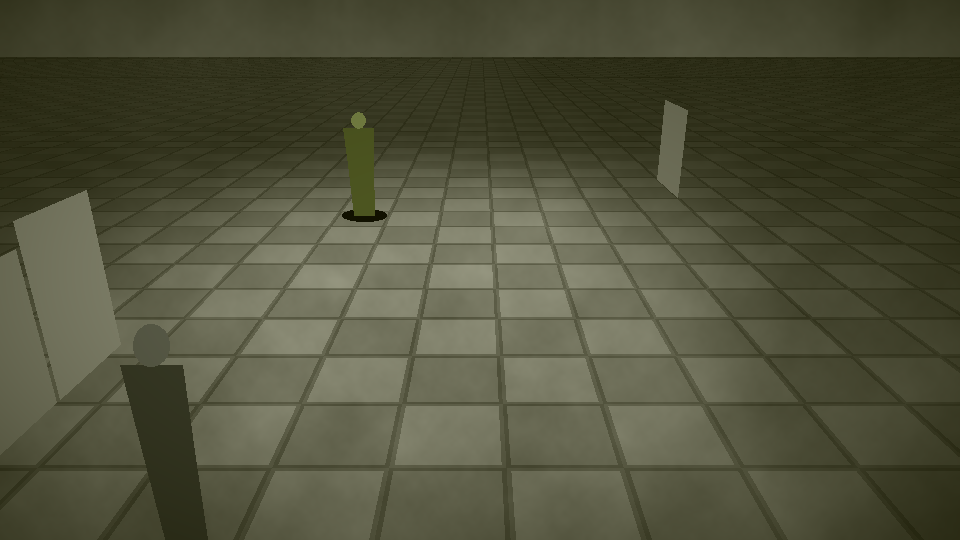

In [3]:
#@title 3a. Data option A - synthetic CCTV scenes (no footage needed)
# Procedural rooms with people at depth-correct scale. Good enough to
# validate the whole chain and to warm-start; weaker than real frames.
!python -m training.synthesize_cctv frames \
    --out data/synth --count 2000 --width 960 --height 540

from IPython.display import Image, display
display(Image('data/synth/clean/000000.png', width=640))

In [4]:
#@title 3b. Real photographs - RUN THIS TOO, it is not optional
#@markdown The synthetic scenes give correct geometry, perspective and
#@markdown lighting, but almost no fine texture: flat figures, clean edges,
#@markdown smooth surfaces. A denoiser trained only on that learns
#@markdown **"smooth is always the right answer"** and then erases facial
#@markdown detail on real footage - which is precisely what GFPGAN and
#@markdown ArcFace need downstream.
#@markdown
#@markdown Denoising is a low-level task, so the content does not have to be
#@markdown surveillance. A few hundred sharp photographs of anything teach
#@markdown the model what real detail looks like. The CCTV-specific half of
#@markdown the problem is the degradation, and that is already simulated.
#@markdown
#@markdown ~430 MB, about a minute on Colab.
!python -m training.fetch_real_data --out data/real --dataset div2k_valid --max_side 1600

# Optional and better still: your own footage. Prop a phone high in a
# corridor, angled down, record 10-15 minutes of people walking through:
#   from google.colab import files; files.upload()
#   !python -m training.make_dataset video --src . --out data/own --fps 2
# then add data/own/clean to DATA_DIRS in cell 5.

dataset : div2k_valid (100 images, ~430 MB)
note    : 100 2K photographs. The usual starting point; plenty for patch-based denoiser training.
url     : http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip

downloading...
  100.0%   449.0 / 449.0 MB
extracting...
  25 / 100
  50 / 100
  75 / 100
  100 / 100
----------------------------------------------------------
wrote 100 real photographs to data/real/clean

mix them with the synthetic scenes:
  python -m training.train_denoiser \
      --train_dir data/synth/clean data/real/clean --arch nano


wrote preview.png (clean + 4 degraded variants)


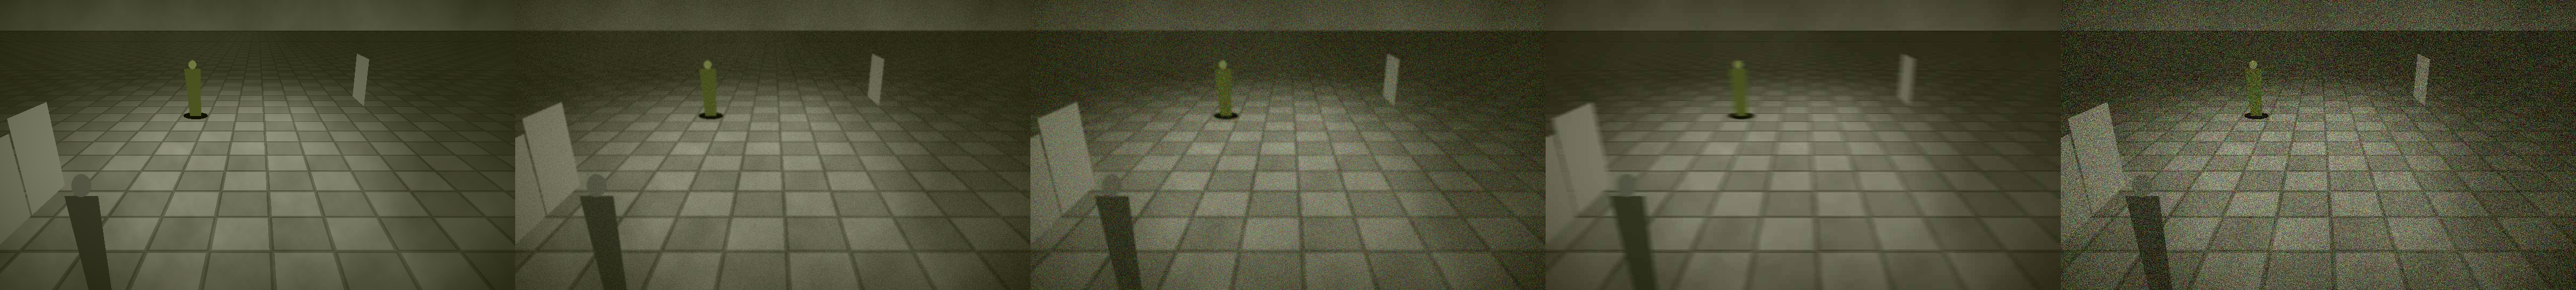

In [5]:
#@title 4. Preview the degradation the model will learn to undo
!python -m training.degradations data/synth/clean/000000.png \
    --preset cctv --n 4 --out preview.png

from IPython.display import Image, display
display(Image('preview.png', width=1100))
# clean | four degraded variants. If these look nothing like your cameras,
# tune training/degradations.py before spending an hour on training.

In [ ]:
#@title 5. Train
#@markdown `nano` is what the Jetson Nano can actually run. `small` is ~4x
#@markdown the cost for roughly +0.5 dB; measure before choosing it.
#@markdown
#@markdown `DATA_DIRS` takes several folders. Keep both: the synthetic
#@markdown frames supply CCTV geometry and lighting, the real photographs
#@markdown supply the texture the model must learn to preserve.
ARCH = 'nano'      #@param ['nano', 'small', 'base']
EPOCHS = 80        #@param {type:'integer'}
PATCH = 128        #@param {type:'integer'}
BATCH = 16         #@param {type:'integer'}
DATA_DIRS = 'data/synth/clean data/real/clean'  #@param {type:'string'}

!python -m training.train_denoiser \
    --train_dir {DATA_DIRS} --arch {ARCH} --preset cctv \
    --epochs {EPOCHS} --patch_size {PATCH} --batch_size {BATCH} \
    --repeat 4 --workers 2 --name nafnet

[dataset] data/synth/clean                               2000 images
[dataset] data/real/clean                                 100 images
[dataset] data/synth/clean                               2000 images
[dataset] data/real/clean                                 100 images
------------------------------------------------------------------
model      : NAFNet w16 enc[1, 1, 1] mid1 dec[1, 1, 1]  (--arch nano)
params     : 0.29M
device     : cuda | amp=True | ema=0.999
train/val  : 7980 / 105 samples
schedule   : 80 epochs x 498 steps = 39840
output     : /content/Re-id-techthrive/runs/nafnet
------------------------------------------------------------------
  epoch   1/80 step    50/498 lr 1.00e-04 loss -15.0152
  epoch   1/80 step   100/498 lr 2.00e-04 loss -17.9387
  epoch   1/80 step   150/498 lr 3.00e-04 loss -19.5830
  epoch   1/80 step   200/498 lr 4.00e-04 loss -20.7011
  epoch   1/80 step   250/498 lr 5.00e-04 loss -21.7532
  epoch   1/80 step   300/498 lr 6.00e-04 loss -22.604

In [ ]:
#@title 6. Look at what it learned
import glob
from IPython.display import Image, display

samples = sorted(glob.glob('runs/nafnet/samples/*.png'))
print('noisy | denoised | clean')
for path in samples[-2:]:
    print(path)
    display(Image(path, width=900))

import pandas as pd
log = pd.read_csv('runs/nafnet/log.csv')
display(log.tail(10))
log.plot(x='epoch', y='val_psnr', figsize=(7, 3), title='validation PSNR (dB)');

In [ ]:
#@title 7. Score it
!python -m training.evaluate --ckpt runs/nafnet/best.pth \
    --data_dir data/synth/clean --limit 40 --max_side 720
# Under about +3 dB means the degradation preset does not match the data.
# Retune degradations.py rather than training for longer.

In [ ]:
#@title 8. Export ONNX and download
#@markdown opset 12 keeps JetPack 4.6's ONNX Runtime 1.11 happy.
!python export/export_onnx.py --ckpt runs/nafnet/best.pth \
    --tile 128 --opset 12 --simplify

# Confirm the exported graph matches the checkpoint before trusting it
!python -m training.evaluate --onnx models/nafnet.onnx \
    --data_dir data/synth/clean --limit 20 --max_side 720

from google.colab import files
files.download('models/nafnet.onnx')

## Then on the Jetson

```bash
# copy nafnet.onnx into models/, then
python3 check_device.py
python3 denoise.py --input_dir some_frames --output_dir out --tile 128 --compare
```

`--compare` writes noisy-vs-denoised strips so you can judge it by eye on
real frames, which is the only test that counts.

Optionally build a TensorRT engine **on the device** (FP16 only — Maxwell
has no INT8):

```bash
python3 export/export_tensorrt.py --onnx models/nafnet.onnx --precision fp16 --benchmark
```